<a href="https://colab.research.google.com/github/andreichukarsen1987/cloud-lab-andreichuk/blob/main/lab_ai_cloud_andreichuk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
import sys, platform

student = "Андрейчук Арсеній"
group = "ПІ-25-01"
print("Лабораторна робота: Gemini, Colab, GitHub")
print("Виконав(ла):", student, "| група:", group)
print("Python:", sys.version.split()[0])
print("Платформа:", platform.system())

Лабораторна робота: Gemini, Colab, GitHub
Виконав(ла): Андрейчук Арсеній | група: ПІ-25-01
Python: 3.13.18
Платформа: Linux


# Лабораторна робота 11: Gemini Notebook, Google Colab і GitHub
**Виконав:** Андрейчук Арсеній Ярославович, група ПІ-25-01
**Варіант:** 1 (Облік дефектів)

Дані навчальні, синтетичні.

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

url = ("https://raw.githubusercontent.com/andreichukarsen1987/"
       "cloud-lab-andreichuk/main/data/bugs.csv")
df = pd.read_csv(url)

print("Кількість дублікатів:", df.duplicated().sum())
print("Розмір таблиці:", df.shape)
df.info()
df.head()

Кількість дублікатів: 0
Розмір таблиці: (30, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            30 non-null     int64  
 1   module        30 non-null     object 
 2   severity      30 non-null     object 
 3   status        30 non-null     object 
 4   hours_to_fix  30 non-null     float64
dtypes: float64(1), int64(1), object(3)
memory usage: 1.3+ KB


,id,module,severity,status,hours_to_fix
0,1,Auth,High,Closed,6.5
1,2,Auth,Low,Closed,1.0
2,3,Cart,Medium,Open,3.0
3,4,Cart,High,Closed,8.0
4,5,Cart,Low,Closed,1.5


## Аналіз даних та побудова діаграми

Описова статистика hours_to_fix:
count    30.000000
mean      4.583333
std       3.657970
min       0.500000
25%       1.500000
50%       3.500000
75%       6.875000
max      14.000000
Name: hours_to_fix, dtype: float64

Середній час виправлення за модулями (год):
module
Auth             4.9
Cart             4.3
Notifications    2.3
Payment          9.2
Profile          3.5
Search           3.1
UI               1.6
Name: hours_to_fix, dtype: float64

Відкриті критичні дефекти:
    id   module severity status  hours_to_fix
7    8  Payment     High   Open          12.0
15  16     Cart     High   Open           7.5
21  22     Auth     High   Open           8.5
26  27   Search     High   Open           7.0
28  29  Payment     High   Open          14.0


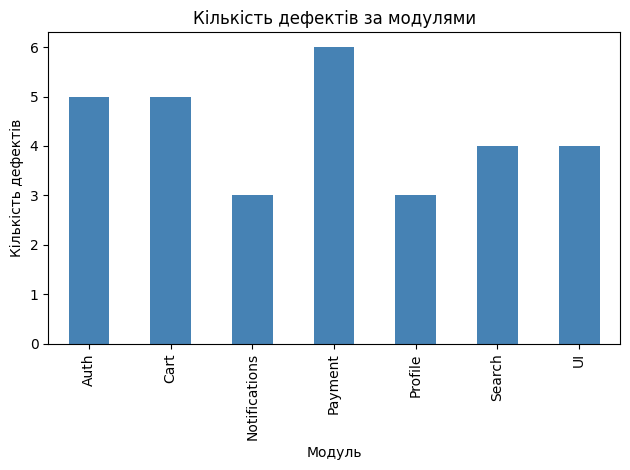

In [24]:
# Описова статистика
print("Описова статистика hours_to_fix:")
print(df["hours_to_fix"].describe())

# Групування: середній час виправлення за модулями
print("\nСередній час виправлення за модулями (год):")
print(df.groupby("module")["hours_to_fix"].mean().round(1))

# Фільтр: відкриті критичні дефекти
critical = df[(df["severity"] == "High") & (df["status"] == "Open")]
print("\nВідкриті критичні дефекти:")
print(critical)

# Побудова діаграми
df.groupby("module")["id"].count().plot(kind="bar", color="steelblue")
plt.title("Кількість дефектів за модулями")
plt.xlabel("Модуль")
plt.ylabel("Кількість дефектів")
plt.tight_layout()
plt.savefig("chart.png", dpi=150)
plt.show()

### Висновки
Найбільша кількість дефектів зафіксована у модулях Payment (6 дефектів) та Auth (5 дефектів), причому в модулі Payment також спостерігається найдовший середній час виправлення — 9.2 години. У наборі даних виявлено 5 відкритих критичних дефектів (рівень High зі статусом Open) у модулях Payment, Cart, Auth та Search. Найшвидше виправляються дефекти в модулях UI та Notifications (у середньому 1.5 та 2.3 години відповідно). Відкриті критичні помилки в модулі Payment потребують першочергового виправлення.

## Додатковий аналіз за допомогою AI-помічника

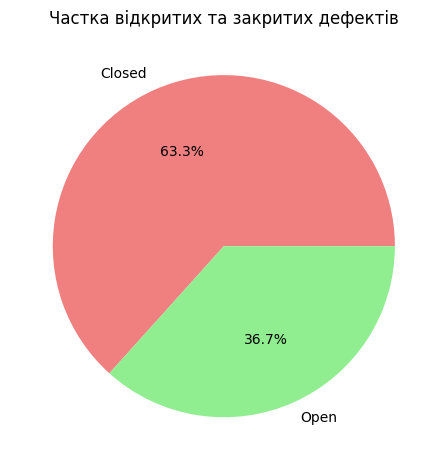

In [25]:
# Додатковий аналіз: частка відкритих і закритих дефектів
df["status"].value_counts().plot(kind="pie", autopct="%1.1f%%", colors=["lightcoral", "lightgreen"])
plt.title("Частка відкритих та закритих дефектів")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [26]:
print(df["severity"].value_counts())

severity
Low       11
High      10
Medium     9
Name: count, dtype: int64


### Журнал AI

| № | Запит | Відповідь AI | Що зробив(ла) я |
|---|---|---|---|
| 1 | «Додай діаграму частки відкритих і закритих дефектів для DataFrame зі стовпцем status» | Запропонував код із `df["status"].value_counts().plot(kind="pie")` | Запустив код, додав заголовок `plt.title(...)` та відсотки `autopct`; перевірив, що сума значень збігається з 30 рядками у `df` |
| 2 | «Поясни помилку KeyError: 'sever' у pandas» | Вказав, що стовпця з назвою `'sever'` немає в DataFrame; ймовірно, це друкарська помилка | Звірив назви стовпців через `df.columns`, виправив `'sever'` на `'severity'` та перезапустив комірку |